# Robotics: a serial robot

Notebook `python/Notebooks/tutorialRobotics.ipynb`.

The Puma560 of `exudyn.robotics.models` as a `Robot`: its kinematics and inverse kinematics without a model, a
trajectory of a joint space and a Cartesian motion with blending, the robot as kinematic tree with the joint control
and the compensation of its dynamics, and the joint coordinates measured by sensors. The outputs below each cell are
those of the last run.

In [1]:
import exudyn as exu
import exudyn.graphics as graphics
from exudyn.robotics import Robot, RobotBase, VRobotBase, RobotTool, VRobotTool
from exudyn.robotics.models import ManipulatorPuma560, LinkDict2Robot
from exudyn.robotics.motion import Trajectory, ProfileConstantAcceleration, ProfileCartesianLinear
from exudyn.interactive import ShowImage
import numpy as np

SC = exu.SystemContainer()
mbs = SC.AddSystem()

## The robot

`LinkDict2Robot` builds a `Robot` from the dictionary of a model: the links by their Denavit-Hartenberg parameters,
masses, centers of mass, inertias, joint limits and the P and D values of the joint control. The robot given as
`robotClass` brings gravity, a base and a tool with their graphics; `initialConfiguration='qn'` starts it in one of
the configurations the model names, the nominal configuration of the Robotics Toolbox with the arm bent forward
(`friction=True` would give the joints the friction of the model).

In [2]:
toolGraphics = [graphics.Cylinder([0,0,-0.06], [0,0,0.02], radius=0.035, color=graphics.color.darkgrey),
                graphics.Brick([0,-0.02,-0.02], [0.03,0.006,0.06], color=graphics.color.lightgrey),
                graphics.Brick([0, 0.02,-0.02], [0.03,0.006,0.06], color=graphics.color.lightgrey)]
baseGraphics = [graphics.Cylinder([0,0,-0.6], [0,0,0.6], radius=0.1, color=graphics.color.grey),
                graphics.CheckerBoard([0.3,0,-0.6], size=1.6, nTiles=8)]
robot = LinkDict2Robot(ManipulatorPuma560(),
                       robotClass=Robot(gravity=[0,0,-9.81],
                                        base=RobotBase(visualization=VRobotBase(graphicsData=baseGraphics)),
                                        tool=RobotTool(HT=exu.HT(translation=[0,0,0.05]),
                                                       visualization=VRobotTool(graphicsData=toolGraphics))),
                       initialConfiguration='qn')
print('links:', robot.NumberOfLinks(), ', q0 =', np.round(robot.q0, 4))

links: 6 , q0 = [ 0.      0.7854 -3.1416  0.      0.7854  0.    ]


## Kinematics without a model

`GetKinematicChain()` gives the kinematics in C++: the tool frame, the Jacobian, the static torques of gravity and the
inverse dynamics, each in a few microseconds. The analytic inverse kinematics finds all configurations of a tool
frame; the one nearest to a reference comes first.

In [3]:
chain = robot.GetKinematicChain()
q0 = robot.q0
HT0 = chain.ToolHT(q0)
print('tool position in q0:', np.round(HT0.translation, 4))
print('static torques in q0:', np.round(chain.StaticTorques(q0), 3))

HTgoal = exu.HT(rotation=HT0.rotation, translation=HT0.translation + np.array([0.1, 0.2, -0.15]))
solutions = robot.InverseKinematicsAnalytic(HTgoal, qReference=q0)
print(len(solutions), 'configurations reach the goal; the nearest:', np.round(solutions[0], 4))

tool position in q0: [ 0.6463 -0.1501 -0.0144]
static torques in q0: [ 0.000e+00 -3.164e+01 -6.035e+00 -0.000e+00 -2.800e-02 -0.000e+00]
8 configurations reach the goal; the nearest: [ 0.2882  0.3877 -2.7716  0.3875  0.8514 -0.2628]


## A trajectory

A `Trajectory` consists of profiles: here a motion of the joints with constant acceleration phases to the goal of the
inverse kinematics, a straight line of the tool and the way back. `blendTimeWithNext` lets the next profile start
before the present one has ended, so that the robot passes near the via point without stopping; `GetBlendings`
says how close.

In [4]:
trajectory = Trajectory(initialCoordinates=q0, initialTime=0.2)
trajectory.Add(ProfileConstantAcceleration(solutions[0], 0.8), blendTimeWithNext=0.2)
HTline = exu.HT(rotation=HTgoal.rotation, translation=HTgoal.translation + np.array([-0.2, 0, 0]))
trajectory.Add(ProfileCartesianLinear(robot, HTline, 0.8))
trajectory.Add(ProfileConstantAcceleration(q0, 0.8))
print('profiles end at', np.round(trajectory.GetTimes(), 3), 's')
for d in trajectory.GetBlendings(chain):
    print('blending: the tool passes the via point at', round(d['toolMinDistance'], 4), 'm')

profiles end at [0.2 1.  1.6 2.4] s
blending: the tool passes the via point at 0.0082 m


## The model, its control and its sensors

`CreateKinematicTree` builds the robot in minimal coordinates (`CreateRedundantCoordinateMBS` would build rigid bodies
and joints). `SetControl` gives the PD control of the joints the trajectory, and `compensation='dynamic'` adds the
joint torques of the inverse dynamics, so that the control only corrects the errors. `PreStepControl` is the
PreStepUserFunction that does this in every step; `AddSensors` measures the joints.

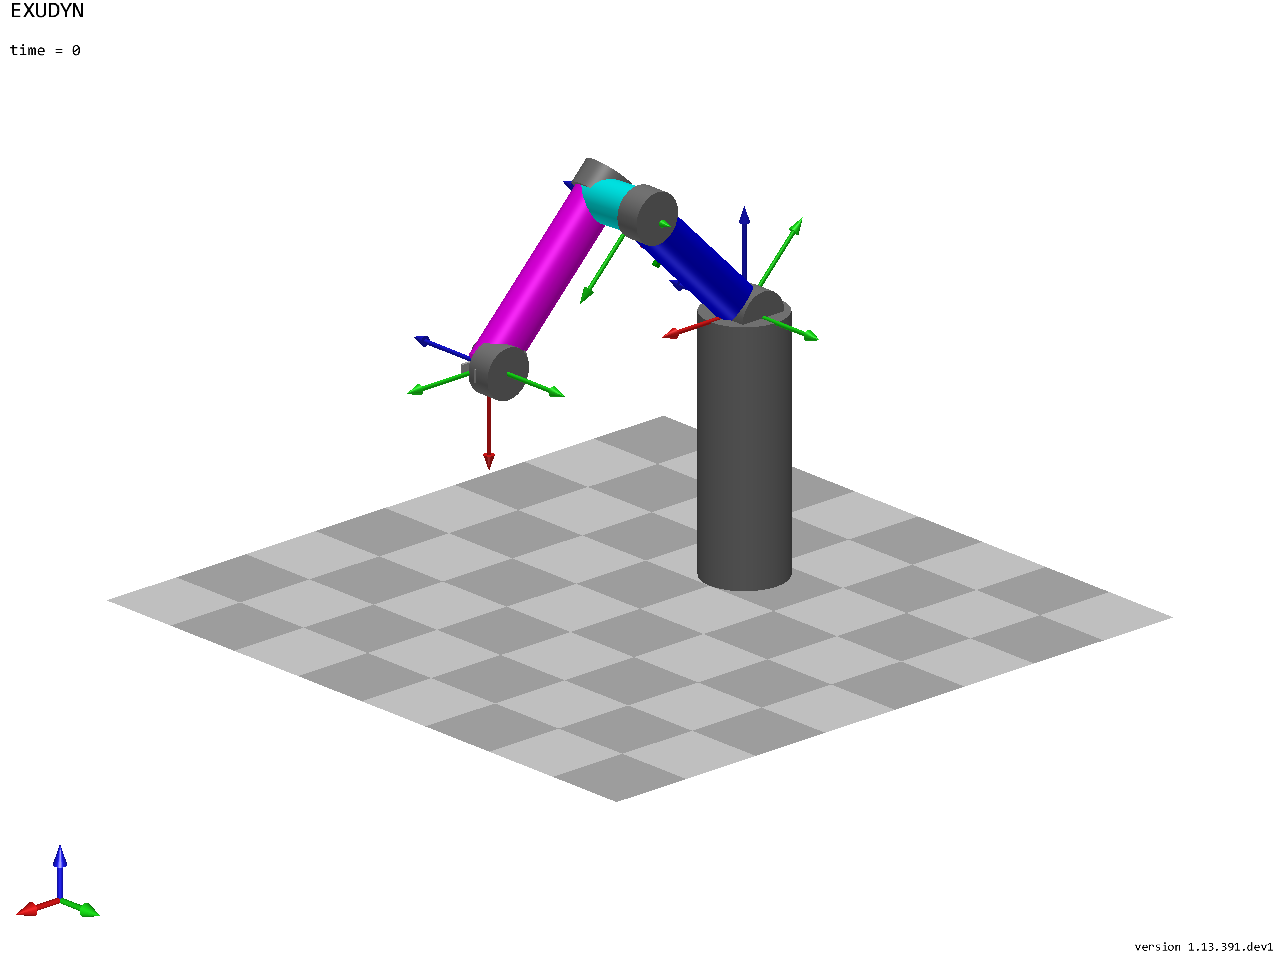

In [5]:
robot.CreateKinematicTree(mbs)
robot.SetControl(trajectory, compensation='dynamic')
mbs.SetPreStepUserFunction(robot.PreStepControl)
sensors = robot.AddSensors(mbs, [exu.OutputVariableType.Coordinates, exu.OutputVariableType.Force])
mbs.Assemble()

SC.visualizationSettings.nodes.show = False
SC.visualizationSettings.view0.scene.drawWorldBasis = False
view = np.array(exu.rigidBodyUtilities.RotationMatrixX(-1.2) @ exu.rigidBodyUtilities.RotationMatrixZ(-2.4)).T
image = ShowImage(SC, size=[1280, 960], modelRotation=view)

In [6]:
tEnd = trajectory.GetTimes()[-1] + 0.3
simulationSettings = exu.SimulationSettings()
simulationSettings.timeIntegration.numberOfSteps = int(tEnd/0.002)
simulationSettings.timeIntegration.endTime = tEnd
simulationSettings.timeIntegration.verboseMode = 0
simulationSettings.solution.sensors.writePeriod = 0.01
mbs.SolveDynamic(simulationSettings)

data = mbs.GetSensorStoredData(sensors[exu.OutputVariableType.Coordinates])
error = max(np.max(np.abs(row[1:] - trajectory.Evaluate(row[0])[0])) for row in data)
print('the largest deviation from the trajectory:', round(error, 6), 'rad')

the largest deviation from the trajectory: 5e-05 rad


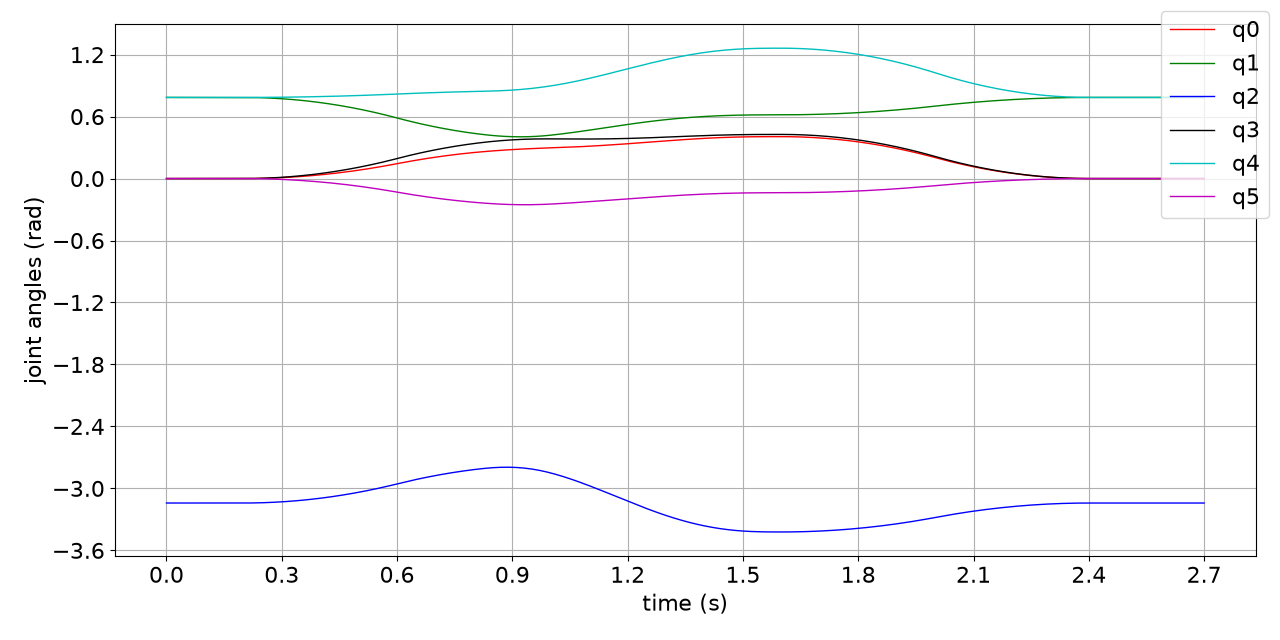

In [7]:
mbs.PlotSensor(sensors[exu.OutputVariableType.Coordinates], components=list(range(6)),
               labels=['q'+str(i) for i in range(6)], yLabel='joint angles (rad)', closeAll=True)

The joint torques of the drives follow from the same sensors; `mbs.SolutionViewer()` replays the motion in the render
window. The examples `staubliTX2blending.py`, `serialRobotKinematicTree.py` and `serialRobotTSD.py` go further.

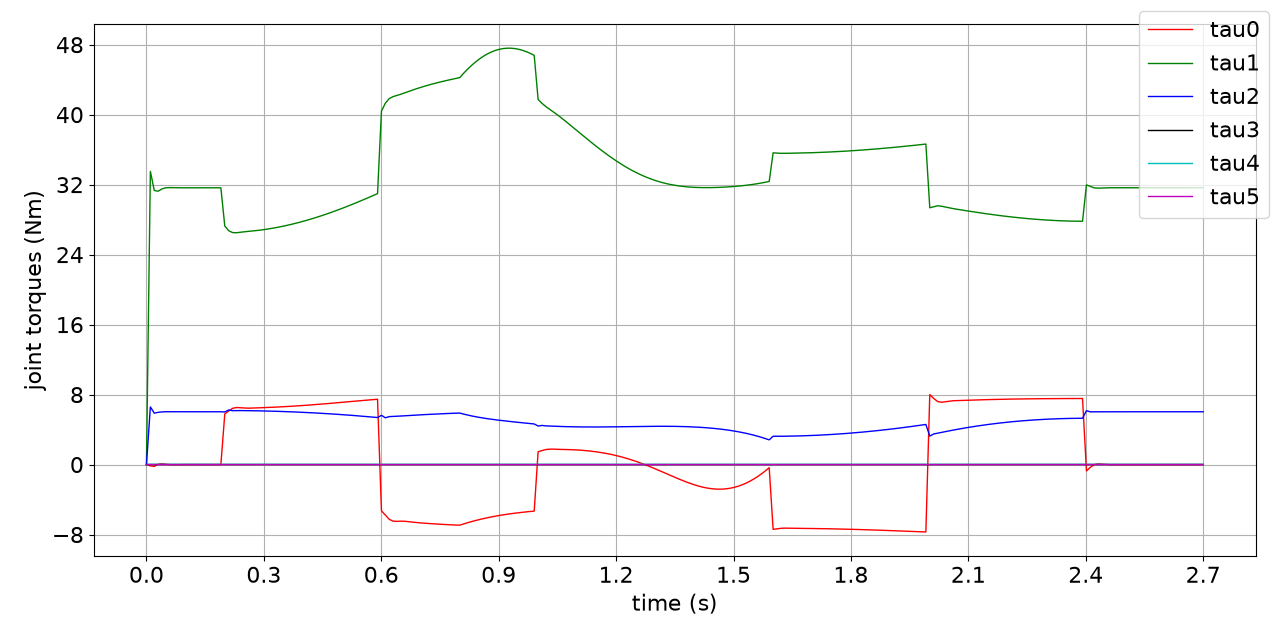

In [8]:
mbs.PlotSensor(sensors[exu.OutputVariableType.Force], components=list(range(6)),
               labels=['tau'+str(i) for i in range(6)], yLabel='joint torques (Nm)')